# So sánh 4 mô hình – tổng quan

**Câu hỏi:** trên cùng một luật chơi (11 mùa test 2010–2020, rolling origin theo năm, tầm 8/16/32 ngày),
bản chính của mỗi thành viên (**GAM**, **LightGBM thô**, **Chronos-2**) có dự báo diện tích ngập ĐBSCL tốt hơn
mốc **AnomAR1** không?

Notebook này không học lại mô hình nào. Mọi số tính lại từ `results/<Mô hình>/tables/predictions.csv`
bằng `src/Comparison/comparison_tables.py`, hình vẽ bằng `comparison_figures.py`; kết quả nằm ở `results/Comparison/`.
Notebook của từng mô hình (`notebooks/<Mô hình>/`) giải thích mô hình đó; notebook này chỉ đặt chúng cạnh nhau.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parents[1]          # notebooks/Comparison -> gốc repo
sys.path.insert(0, str(ROOT / "src" / "Comparison"))
TABLES = ROOT / "results" / "Comparison" / "tables"
FIGURES = ROOT / "results" / "Comparison" / "figures"

from comparison_tables import HORIZON_DAYS, MAIN, RESULTS, SOURCES, baseline_check, load_all
pd.set_option("display.width", 200)

## 1. Kết luận một câu

In [2]:
tests = pd.read_csv(TABLES / "vs_anom_ar1_all.csv")
for row in tests[tests["role"] == "main"].itertuples():
    print(f"{row.model:>9}, {HORIZON_DAYS[row.h]:>2} ngày: RMSE / AnomAR1 = {row.rmse_ratio:.3f}, "
          f"thắng {row.wins}/11, p Holm (9) = {row.p_t_holm_main:.3f}, p TOST ±5% = {row.p_tost:.3f}")

      gam,  8 ngày: RMSE / AnomAR1 = 1.006, thắng 5/11, p Holm (9) = 1.000, p TOST ±5% = 0.002
      gam, 16 ngày: RMSE / AnomAR1 = 0.997, thắng 7/11, p Holm (9) = 1.000, p TOST ±5% = 0.053
      gam, 32 ngày: RMSE / AnomAR1 = 1.001, thắng 7/11, p Holm (9) = 1.000, p TOST ±5% = 0.253
 lgbm_raw,  8 ngày: RMSE / AnomAR1 = 0.965, thắng 5/11, p Holm (9) = 1.000, p TOST ±5% = 0.363
 lgbm_raw, 16 ngày: RMSE / AnomAR1 = 0.933, thắng 9/11, p Holm (9) = 1.000, p TOST ±5% = 0.511
 lgbm_raw, 32 ngày: RMSE / AnomAR1 = 1.001, thắng 5/11, p Holm (9) = 1.000, p TOST ±5% = 0.293
 chronos2,  8 ngày: RMSE / AnomAR1 = 1.024, thắng 4/11, p Holm (9) = 1.000, p TOST ±5% = 0.216
 chronos2, 16 ngày: RMSE / AnomAR1 = 1.027, thắng 2/11, p Holm (9) = 1.000, p TOST ±5% = 0.211
 chronos2, 32 ngày: RMSE / AnomAR1 = 1.060, thắng 2/11, p Holm (9) = 0.045, p TOST ±5% = 0.748


**Không mô hình nào tốt hơn AnomAR1 có ý nghĩa** sau khi hiệu chỉnh cho 9 phép so (3 mô hình × 3 tầm).

- **LightGBM thô** có RMSE thấp nhất ở 8 và 16 ngày (tỉ lệ 0,965 và 0,933; thắng 9/11 mùa ở 16 ngày), nhưng khoảng
  tin cậy rộng và p sau Holm = 1. Đây là tín hiệu đáng thử lại trên dữ liệu mới, chưa phải kết luận.
- **GAM** gần như trùng AnomAR1; ở 8 ngày có bằng chứng **tương đương** trong ±5% RMSE (p TOST = 0,002).
- **Chronos-2** (zero-shot) **kém hơn** AnomAR1 ở 32 ngày, và vẫn có ý nghĩa sau Holm toàn cục (p = 0,045;
  chênh MSE +14%, CI 95% +4% đến +25%).

## 2. Mọi người cùng một mốc

Mỗi thư mục kết quả tự chạy lại AnomAR1 để so sánh. Trước khi gộp, `baseline_check` kiểm tra cột `anom_ar1` của
4 thư mục có cùng số dòng và cùng giá trị (lệch tối đa khoảng 1e-12 km², chỉ là sai số làm tròn). Nếu lệch,
`load_all` dừng và báo lỗi. Mỗi mô hình sau đó được lấy đúng một lần, từ thư mục sở hữu nó.

Chi tiết: `comparison_tables.py::baseline_check`, `comparison_tables.py::load_all`

In [3]:
display(baseline_check())
pred = load_all()
display(pred.groupby(["source", "model"]).size().rename("số dòng").to_frame())

,source,n_rows,same_rows,max_abs_diff
0,AnomAR1,748,True,0.000000e+00
1,GAM,748,True,9.094947e-13
2,LightGBM,748,True,0.000000e+00
3,Chronos-2,748,True,0.000000e+00


số dòng
source    model                
AnomAR1   anom_ar1          748
          anom_ar1_w7       748
          clim5             748
          persistence       748
Chronos-2 chronos2          748
GAM       gam               748
          gam_w7            748
LightGBM  lgbm_anomaly      748
          lgbm_noclim       748
          lgbm_raw          748

## 3. RMSE gộp

Cột `role`: `baseline` là mốc, `main` là bản chính khai báo trước của mỗi thành viên, `variant` là biến thể phụ,
`simple` là mốc đơn giản (Clim5 = trung bình 5 mùa trước, Persistence = giữ nguyên giá trị hôm nay).
Ba bản chính và AnomAR1 nằm sát nhau; Persistence tệ dần rất nhanh theo tầm.

Chi tiết: `comparison_tables.py::rmse_all`, `comparison_figures.py::fig_rmse_by_horizon`

,source,role,1,2,4
model,,,,,
anom_ar1,AnomAR1,baseline,1090.0,1375.0,1687.0
gam,GAM,main,1096.0,1372.0,1688.0
lgbm_raw,LightGBM,main,1051.0,1284.0,1688.0
chronos2,Chronos-2,main,1116.0,1412.0,1788.0
anom_ar1_w7,AnomAR1,variant,1084.0,1355.0,1682.0
gam_w7,GAM,variant,1090.0,1378.0,1711.0
lgbm_anomaly,LightGBM,variant,1101.0,1364.0,1699.0
lgbm_noclim,LightGBM,variant,1059.0,1301.0,1778.0
clim5,AnomAR1,simple,1812.0,1845.0,1916.0


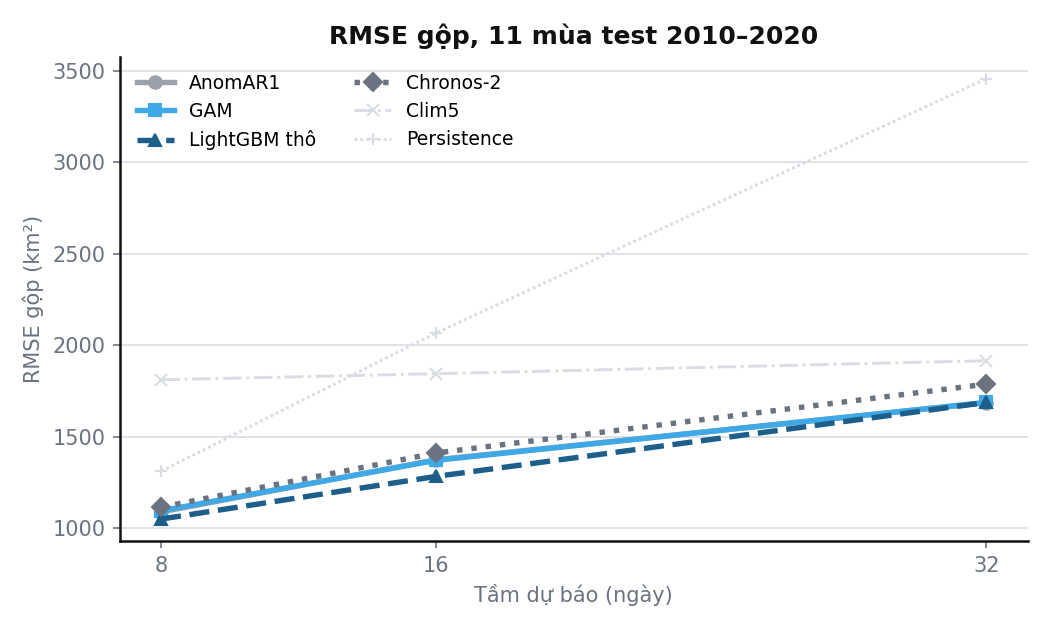

In [4]:
display(pd.read_csv(TABLES / "rmse_all.csv").set_index("model"))
display(Image(FIGURES / "rmse_by_horizon.png", width=700))

## 4. Kiểm định cấp mùa, Holm trên 9 phép so

Đơn vị so sánh là **mùa** (n = 11) vì sai số các bước liền nhau trong một mùa tương quan mạnh.
Mỗi mô hình trong thư mục riêng chỉ hiệu chỉnh Holm trong các phép so của nó (cột `p_t_holm_own`). Khi đặt 3 bản chính
cạnh nhau, nhóm làm 9 phép so với AnomAR1, nên `p_t_holm_main` hiệu chỉnh trên cả 9. Kết luận không đổi: chỉ
Chronos-2 ở 32 ngày có ý nghĩa (kém hơn). Biến thể và mốc đơn giản có trong `vs_anom_ar1_all.csv` với p thô,
không vào họ hiệu chỉnh này.

Chi tiết: `comparison_tables.py::compare_with_anom_ar1`, `comparison_tables.py::holm`

In [5]:
main = tests[tests["role"] == "main"].set_index(["model", "h"])
own = pd.concat([pd.read_csv(RESULTS / s / "tables" / "vs_anom_ar1.csv") for s in ["GAM", "LightGBM", "Chronos-2"]])
own = own.set_index(["model", "h"]).loc[main.index, "p_t_holm"]
display(main[["rmse_ratio", "wins", "mse_diff_pct", "mse_diff_pct_ci_low", "mse_diff_pct_ci_high",
              "p_t", "p_tost", "p_t_holm_main"]].assign(**{"p_t_holm_own": own}))

rmse_ratio  wins  mse_diff_pct  mse_diff_pct_ci_low  mse_diff_pct_ci_high     p_t  p_tost  p_t_holm_main  p_t_holm_own
model    h                                                                                                                        
gam      1      1.0058     5        2.2118              -2.7918                7.2155  0.5076  0.0017         1.0000        1.0000
         2      0.9973     7        2.0291             -10.4721               14.5304  0.9137  0.0530         1.0000        1.0000
         4      1.0006     7        9.4050             -23.0392               41.8493  0.9896  0.2526         1.0000        1.0000
lgbm_raw 1      0.9648     5       -4.8572             -18.6522                8.9378  0.4076  0.3635         1.0000        1.0000
         2      0.9335     9       -5.2714             -26.9523               16.4096  0.1397  0.5113         1.0000        1.0000
         4      1.0008     5       11.7915             -23.9135               47.4965  0.9895  0.2929         1.0000        1.0000
chronos2 1      1.0240     4        7.7421              -1.0148               16.4990  0.3026  0.2157         1.0000        0.6051
         2      1.0266     2        7.2345              -2.3514               16.8204  0.3455  0.2108         1.0000        0.6051
         4      1.0601     2       14.2783               4.0393               24.5173  0.0050  0.7480         0.0453        0.0151

## 5. Từng mùa test

Mỗi điểm là tỉ lệ RMSE của một mùa so với AnomAR1 cùng mùa. Ở 32 ngày, GAM và LightGBM có vài mùa tệ hơn rất
nhiều (tỉ lệ 1,3–1,6) xen với vài mùa tốt hơn: trung bình gần 1 nhưng biến động lớn. Chronos-2 nằm phía trên 1
ở hầu hết các mùa khi tầm dài.

Chi tiết: `comparison_tables.py::season_table`, `comparison_figures.py::fig_season_ratio`

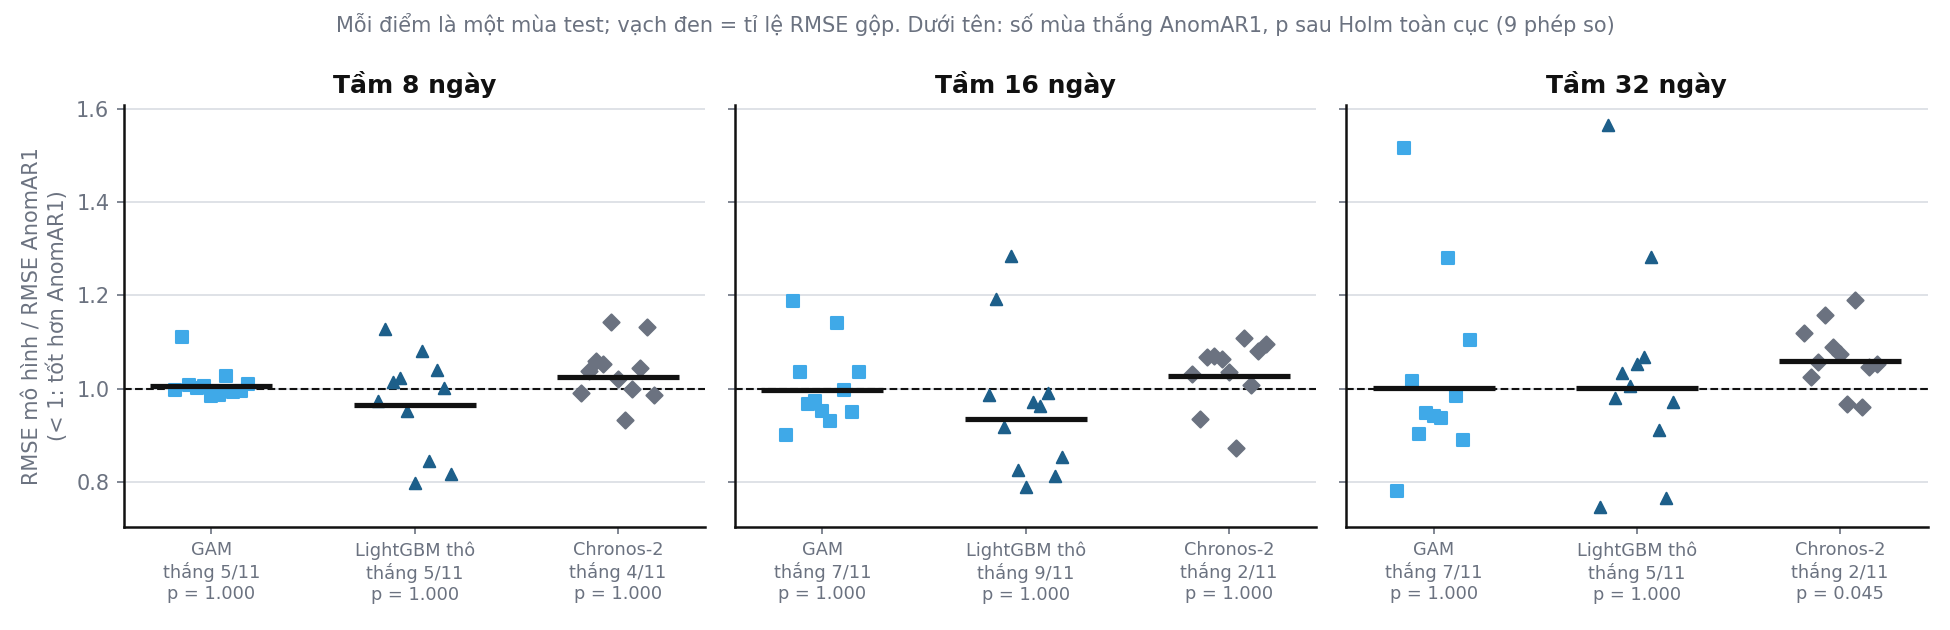

model,gam,lgbm_raw,chronos2
season,,,
2010,0.900,0.986,1.031
2011,1.189,1.193,0.934
2012,1.035,0.917,1.067
2013,0.966,1.284,1.069
2014,0.974,0.824,1.064
2015,0.953,0.788,1.035
2016,0.931,0.972,0.872
2017,1.140,0.962,1.108
2018,0.997,0.990,1.008


In [6]:
display(Image(FIGURES / "season_ratio.png", width=950))
s = pd.read_csv(TABLES / "season_rmse.csv")
display(s[s["h"] == 2].pivot(index="season", columns="model", values="ratio_vs_anom_ar1")[MAIN[1:]].round(3))

## 6. Theo điều kiện (chỉ mô tả)

Giai đoạn lũ theo ngày đích (nước lên < 257, đỉnh 257–297, nước rút ≥ 298); cỡ lũ chia 11 mùa test thành 3 nhóm theo
đỉnh. Cùng định nghĩa và cùng dạng bảng với `rmse_by_phase.csv` / `rmse_by_size.csv` của từng mô hình.

- LightGBM thô khá hơn khi **nước lên** và **nước rút** ở 8–16 ngày, nhưng kém hơn ở **đỉnh**.
- Mùa **lũ nhỏ** là nơi LightGBM khá hơn rõ nhất (RMSE thấp hơn AnomAR1 11–15% ở 8–16 ngày).
- Chronos-2 ở 32 ngày kém nhất khi **nước rút**.

Các nhóm này được chia sau khi có kết quả và không kiểm định, nên chỉ dùng để gợi ý, không để kết luận.

Chi tiết: `comparison_tables.py::condition_table`, `comparison_figures.py::fig_conditions`

rising    peak  falling
h model                            
1 anom_ar1   897.0  1068.0   1304.0
  gam        886.0  1096.0   1311.0
  lgbm_raw   842.0  1180.0   1177.0
  chronos2   900.0  1152.0   1314.0
2 anom_ar1  1154.0  1391.0   1578.0
  gam       1121.0  1408.0   1584.0
  lgbm_raw  1048.0  1531.0   1321.0
  chronos2  1134.0  1468.0   1633.0
4 anom_ar1  1357.0  1692.0   1927.0
  gam       1251.0  1708.0   1981.0
  lgbm_raw  1225.0  1742.0   1973.0
  chronos2  1410.0  1658.0   2144.0

small  medium   large
h model                           
1 anom_ar1  1179.0  1196.0   896.0
  gam       1175.0  1194.0   923.0
  lgbm_raw  1046.0  1205.0   925.0
  chronos2  1220.0  1199.0   926.0
2 anom_ar1  1488.0  1367.0  1260.0
  gam       1460.0  1334.0  1307.0
  lgbm_raw  1261.0  1269.0  1318.0
  chronos2  1579.0  1323.0  1295.0
4 anom_ar1  1885.0  1400.0  1675.0
  gam       1826.0  1413.0  1734.0
  lgbm_raw  1767.0  1518.0  1728.0
  chronos2  1972.0  1479.0  1807.0

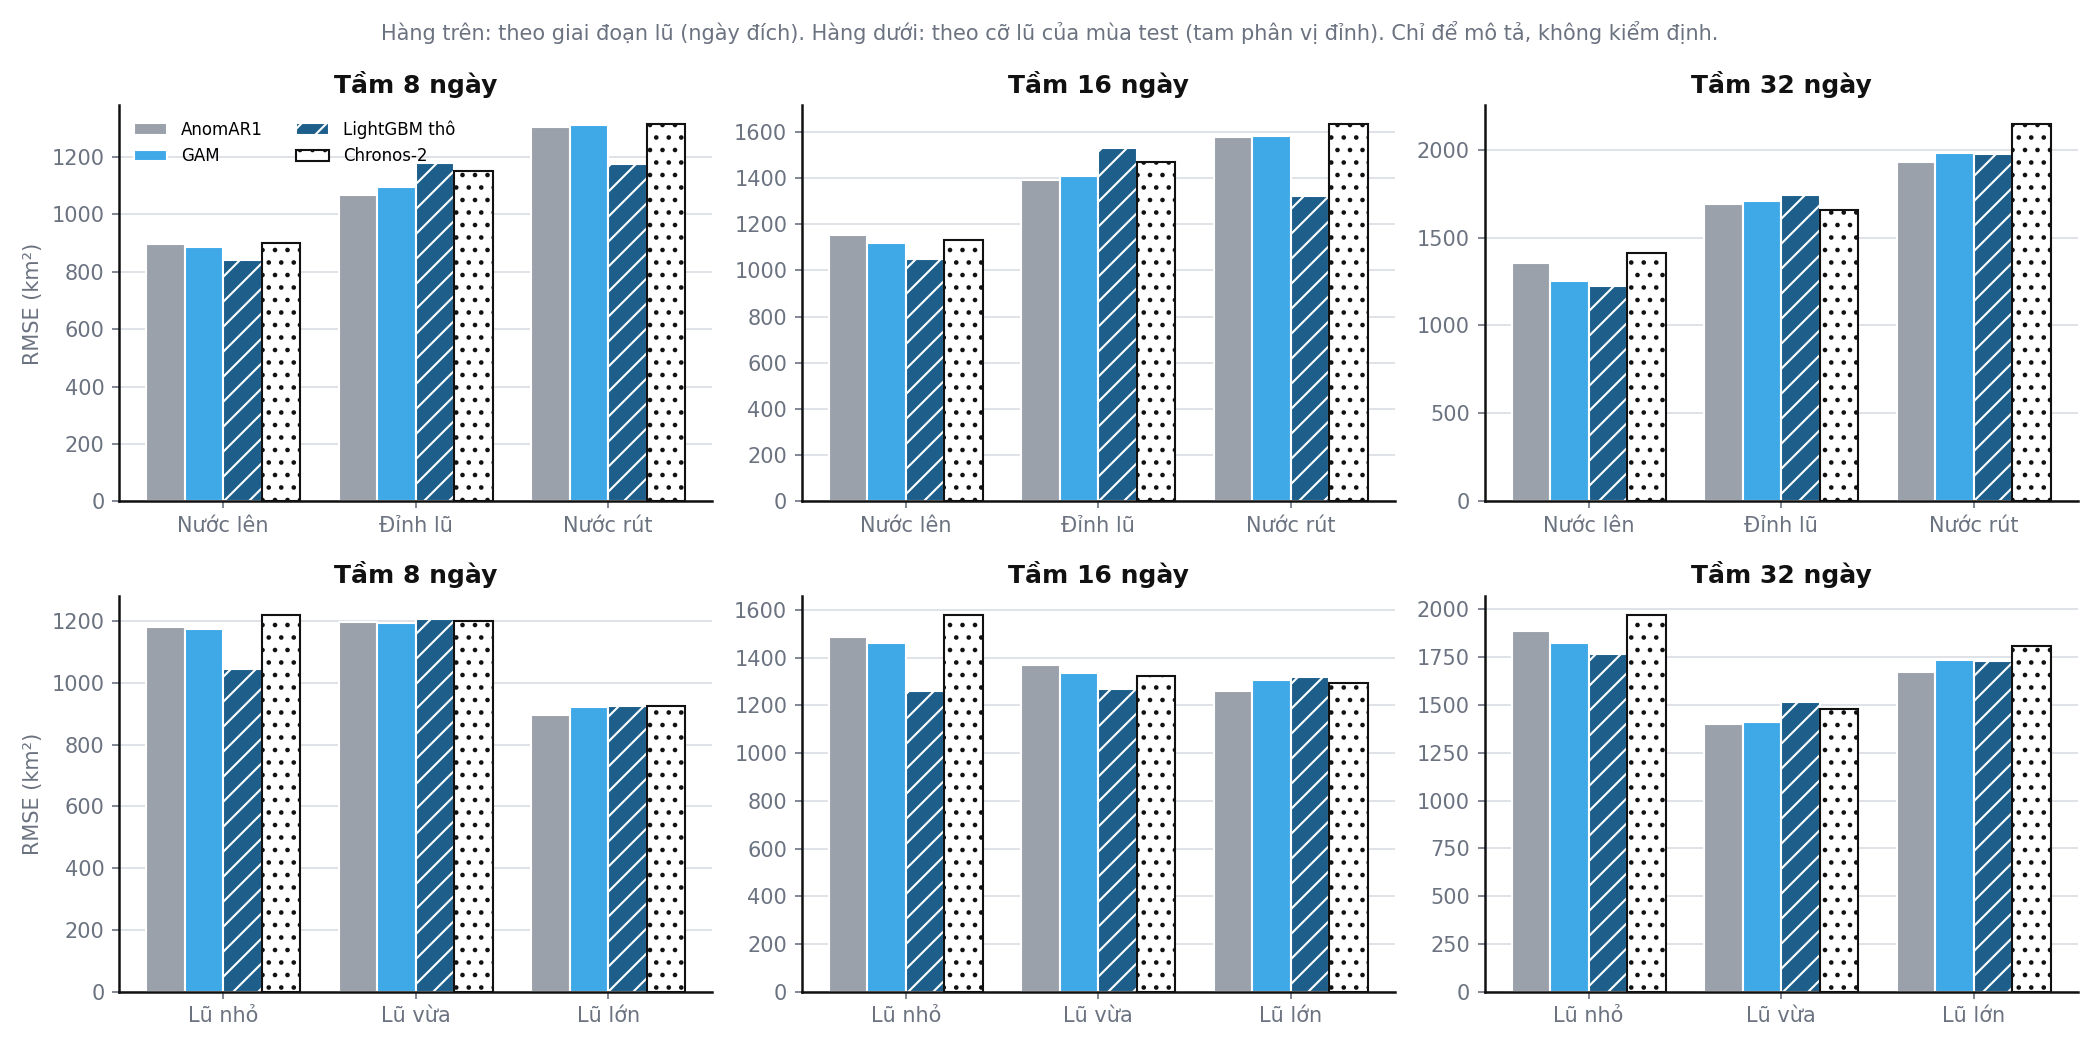

In [7]:
display(pd.read_csv(TABLES / "rmse_by_phase.csv").set_index(["h", "model"]))
display(pd.read_csv(TABLES / "rmse_by_size.csv").set_index(["h", "model"]))
display(Image(FIGURES / "conditions.png", width=950))

## 7. Hai mùa ví dụ

Mùa có đỉnh cao nhất và thấp nhất trong 11 mùa test, dự báo trước 16 ngày. Đường đen là quan sát.

Chi tiết: `comparison_figures.py::fig_example_seasons`

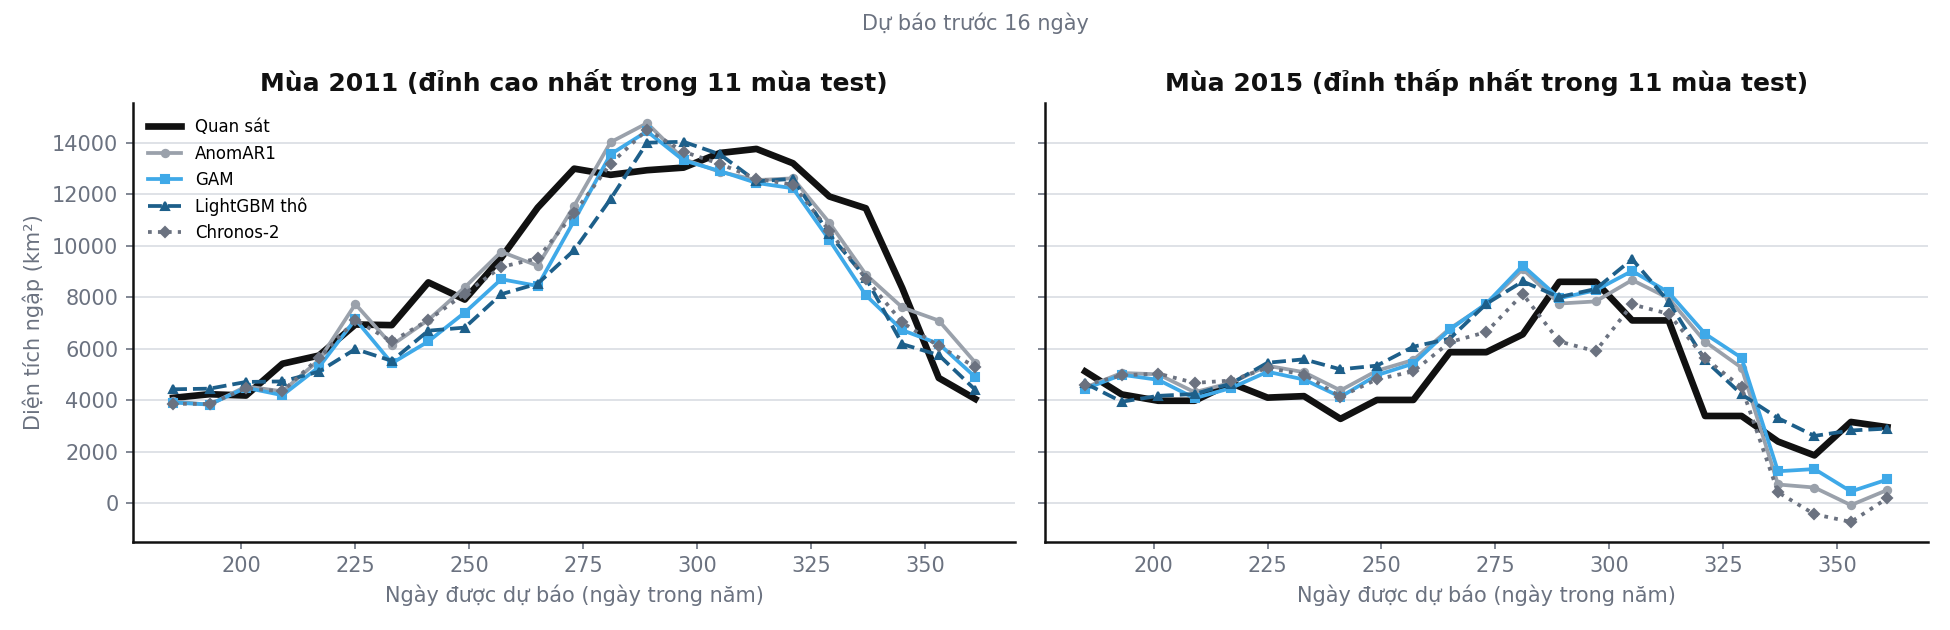

In [8]:
display(Image(FIGURES / "example_seasons.png", width=950))

## 8. Cách nói an toàn và hạn chế

- Nói: "Trên 11 mùa test, không mô hình nào tốt hơn AnomAR1 có ý nghĩa sau hiệu chỉnh Holm cho 9 phép so;
  Chronos-2 zero-shot kém hơn có ý nghĩa ở tầm 32 ngày."
- Không nói "LightGBM tốt nhất": RMSE thấp nhất về số ở 8–16 ngày, nhưng khoảng tin cậy chứa 0.
- "Không khác có ý nghĩa" không có nghĩa "tương đương": chỉ GAM ở 8 ngày có bằng chứng tương đương (TOST).
- n = 11 mùa, một chuỗi toàn vùng: lực kiểm định thấp. Bảng theo điều kiện chỉ để mô tả.
- Chạy lại: `python src/Comparison/comparison_tables.py` rồi `python src/Comparison/comparison_figures.py`
  (sau khi 4 mô hình đã ghi `predictions.csv`); test: `python -m pytest tests/Comparison`.

Xem thêm: `src/Comparison/README.md`.